In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report

# Yoseva Faurensia Sitohang_202431195

In [23]:
# Membaca dataset hasil scraping Soal 2
df = pd.read_csv("pokemon_dataset.csv")

print("Ukuran dataset:", df.shape)
display(df.head())

# Yoseva Faurensia Sitohang_202431195

Ukuran dataset: (1261, 10)


,nomor,nama,tipe,total,hp,attack,defense,sp_attack,sp_defense,speed
0,1,Bulbasaur,Grass Poison,318,45,49,49,65,65,45
1,2,Ivysaur,Grass Poison,405,60,62,63,80,80,60
2,3,Venusaur,Grass Poison,525,80,82,83,100,100,80
3,3,VenusaurMega Venusaur,Grass Poison,625,80,100,123,122,120,80
4,4,Charmander,Fire,309,39,52,43,60,50,65


In [24]:
df.info()

# Yoseva Faurensia Sitohang_202431195

<class 'pandas.DataFrame'>
RangeIndex: 1261 entries, 0 to 1260
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   nomor       1261 non-null   int64
 1   nama        1261 non-null   str  
 2   tipe        1261 non-null   str  
 3   total       1261 non-null   int64
 4   hp          1261 non-null   int64
 5   attack      1261 non-null   int64
 6   defense     1261 non-null   int64
 7   sp_attack   1261 non-null   int64
 8   sp_defense  1261 non-null   int64
 9   speed       1261 non-null   int64
dtypes: int64(8), str(2)
memory usage: 122.7 KB


In [25]:
display(df.describe())

# Yoseva Faurensia Sitohang_202431195

,nomor,total,hp,attack,defense,sp_attack,sp_defense,speed
count,1261.000000,1261.000000,1261.000000,1261.000000,1261.000000,1261.000000,1261.000000,1261.000000
mean,503.420301,449.487708,71.629659,82.458366,75.973830,74.927835,73.596352,70.901665
std,297.941876,123.770336,26.912735,32.785971,30.984816,34.217656,28.025492,30.541564
min,1.000000,175.000000,1.000000,5.000000,5.000000,10.000000,20.000000,5.000000
25%,243.000000,335.000000,55.000000,60.000000,54.000000,50.000000,53.000000,46.000000
50%,500.000000,471.000000,70.000000,80.000000,70.000000,68.000000,70.000000,70.000000
75%,751.000000,530.000000,85.000000,103.000000,95.000000,95.000000,90.000000,92.000000
max,1025.000000,1125.000000,255.000000,190.000000,250.000000,216.000000,250.000000,200.000000


In [26]:
print(df.isna().sum())

# Yoseva Faurensia Sitohang_202431195

nomor         0
nama          0
tipe          0
total         0
hp            0
attack        0
defense       0
sp_attack     0
sp_defense    0
speed         0
dtype: int64


In [27]:
print("Kelas unik tipe Pokémon:")
print(df["tipe"].unique())

# Arti kelas:
# Fire = Api, Water = Air, Grass = Rumput
# Poison = Racun, Flying = Terbang, Electric = Listrik
# Bug = Serangga, Normal = Normal, Ground = Tanah
# Rock = Batu, Psychic = Psikis, Ice = Es
# Dragon = Naga, Ghost = Hantu, Dark = Gelap
# Steel = Baja, Fairy = Peri, Fighting = Petarung

# Kombinasi dua tipe menunjukkan Pokémon memiliki dua tipe.
# Contoh: Grass Poison = Rumput dan Racun.
#         Fire Flying = Api dan Terbang.

# Yoseva Faurensia Sitohang_202431195

Kelas unik tipe Pokémon:
<ArrowStringArray>
[     'Grass Poison',              'Fire',       'Fire Flying',
       'Fire Dragon',             'Water',               'Bug',
        'Bug Flying',        'Bug Poison',     'Normal Flying',
            'Normal',
 ...
   'Electric Ground', 'Fighting Electric',       'Fire Poison',
       'Dark Ground',       'Dragon Dark',    'Fairy Fighting',
   'Fighting Dragon',       'Grass Water',        'Grass Rock',
      'Poison Ghost']
Length: 221, dtype: str


In [28]:
fitur = [
    "total",
    "hp",
    "attack",
    "defense",
    "sp_attack",
    "sp_defense",
    "speed"
]

target = "tipe"

df_model = df.dropna(subset=fitur + [target]).copy()

X = df_model[fitur]
y = df_model[target]

print("Jumlah data:", len(df_model))
print("Fitur X:", fitur)
print("Target y:", target)

# Yoseva Faurensia Sitohang_202431195

Jumlah data: 1261
Fitur X: ['total', 'hp', 'attack', 'defense', 'sp_attack', 'sp_defense', 'speed']
Target y: tipe


In [29]:
X = np.array(X, dtype=np.float64)

encoder = LabelEncoder()
y = encoder.fit_transform(y)

y = np.array(y, dtype=np.int64)

print("Bentuk X:", X.shape)
print("Bentuk y:", y.shape)
print("Jumlah kelas:", len(encoder.classes_))

# Yoseva Faurensia Sitohang_202431195

Bentuk X: (1261, 7)
Bentuk y: (1261,)
Jumlah kelas: 221


In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=0
)

print("Jumlah data latih:", X_train.shape[0])
print("Jumlah data uji:", X_test.shape[0])

# Yoseva Faurensia Sitohang_202431195

Jumlah data latih: 882
Jumlah data uji: 379


In [31]:
model = DecisionTreeClassifier(random_state=0)

model.fit(X_train, y_train)

print("Model Decision Tree berhasil dilatih.")

# Yoseva Faurensia Sitohang_202431195

Model Decision Tree berhasil dilatih.


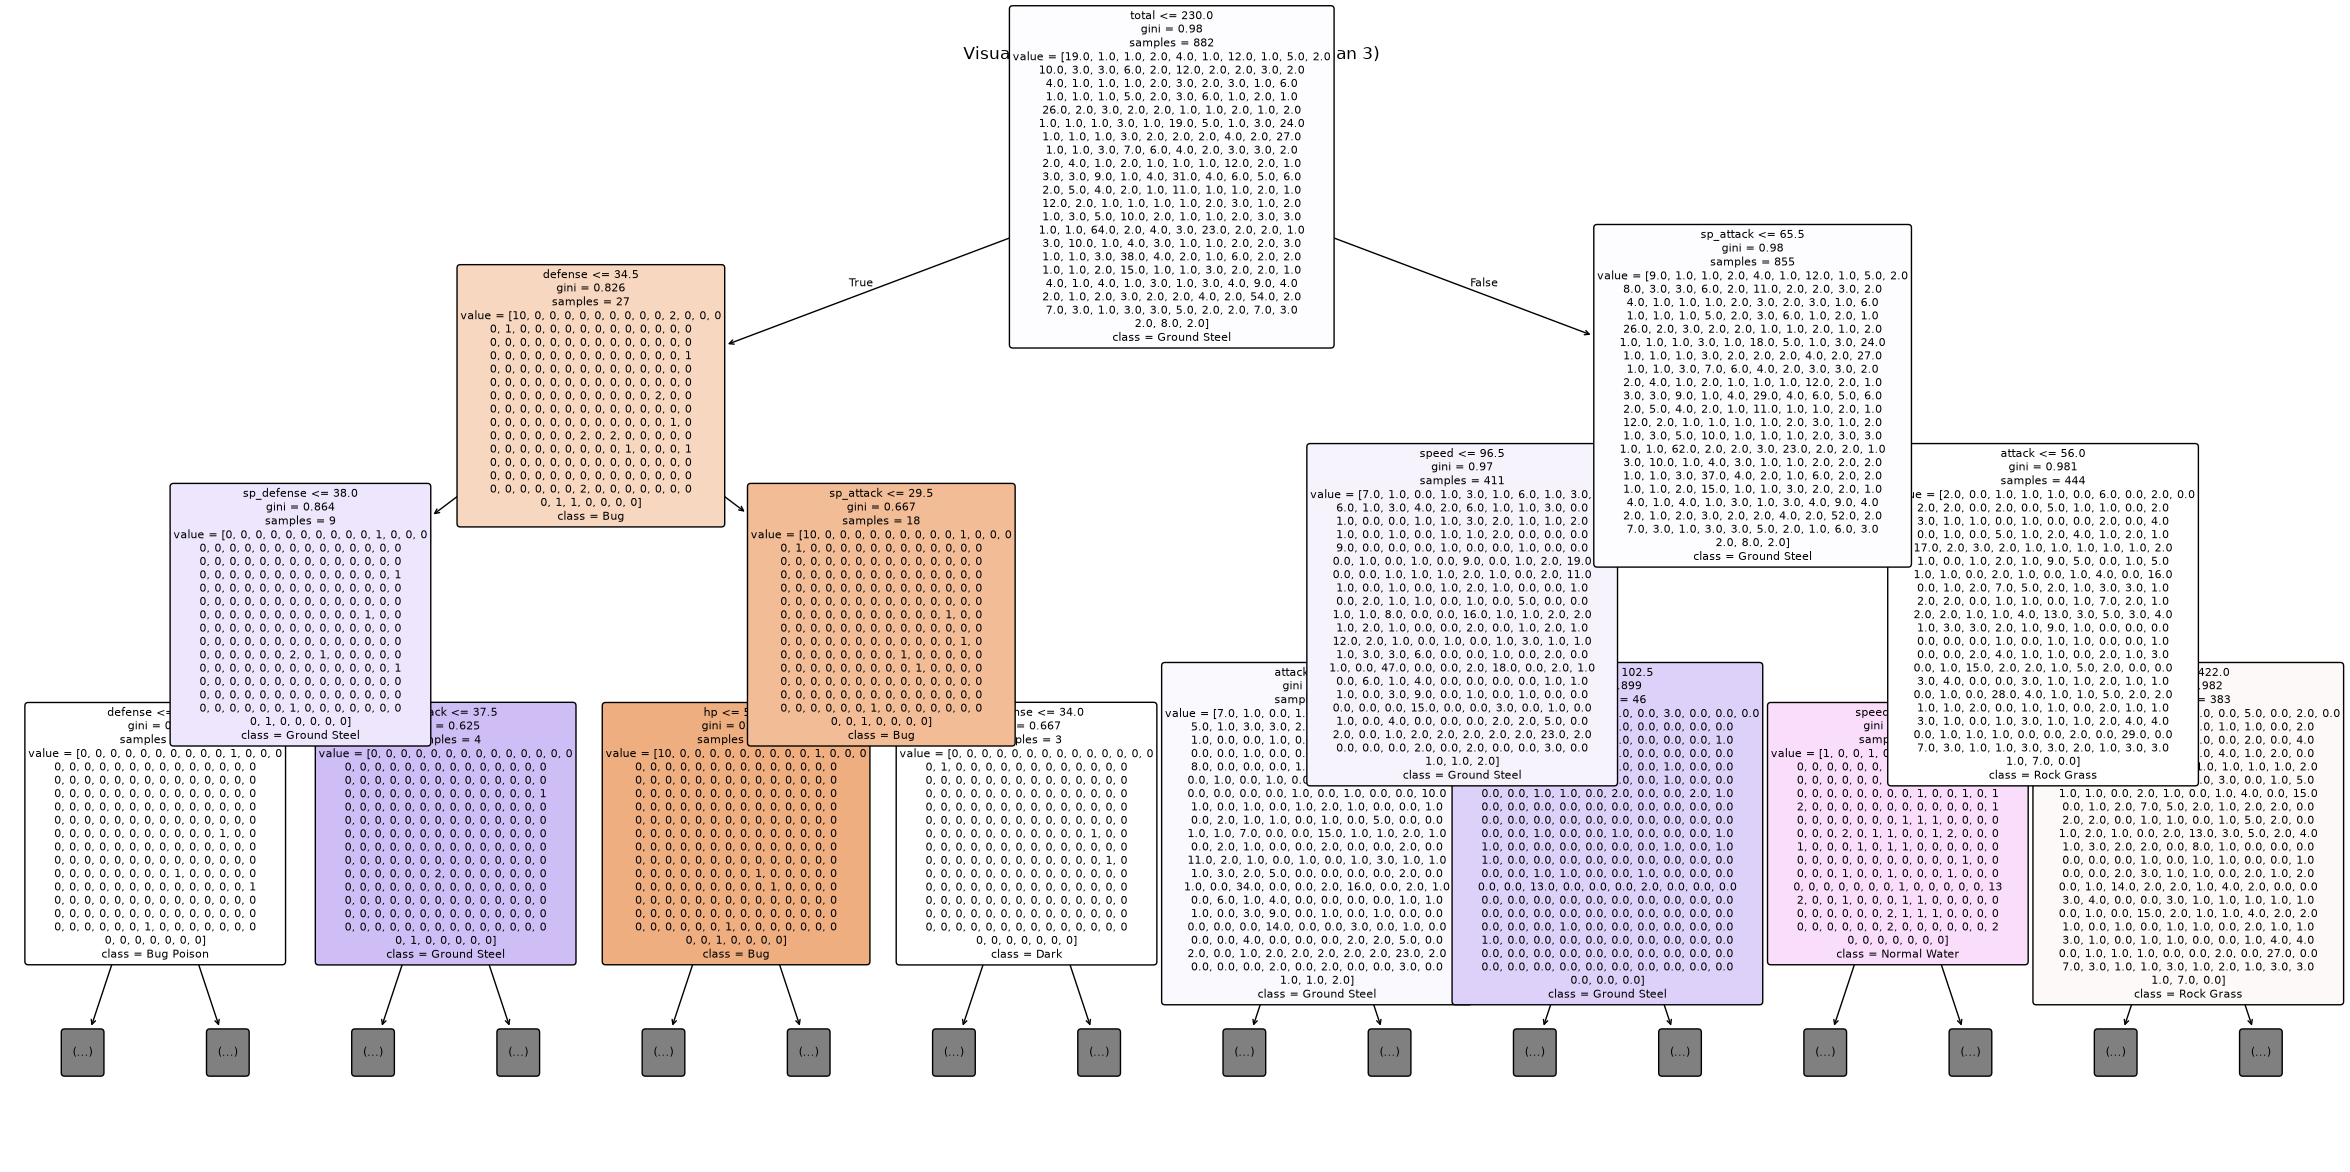

In [32]:
plt.figure(figsize=(24, 12))

plot_tree(
    model,
    feature_names=fitur,
    class_names=encoder.classes_,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Visualisasi Decision Tree Pokémon (Kedalaman 3)")
plt.tight_layout()
plt.show()

# Yoseva Faurensia Sitohang_202431195

In [33]:
data_baru = np.array([[
    318, 45, 49, 49, 65, 65, 45
]], dtype=np.float64)

prediksi = model.predict(data_baru)

tipe_prediksi = encoder.inverse_transform(prediksi)

print("Prediksi tipe Pokémon:", tipe_prediksi[0])

# Yoseva Faurensia Sitohang_202431195

Prediksi tipe Pokémon: Grass Poison


In [34]:
y_pred = model.predict(X_test)

akurasi = accuracy_score(y_test, y_pred)

print("Akurasi Decision Tree:", akurasi)
print("Akurasi dalam persen:", round(akurasi * 100, 2), "%")

# Yoseva Faurensia Sitohang_202431195

Akurasi Decision Tree: 0.0712401055408971
Akurasi dalam persen: 7.12 %


In [35]:
print("Classification Report:")

print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))

# Yoseva Faurensia Sitohang_202431195

Classification Report:
                   precision    recall  f1-score   support

              Bug       0.29      0.33      0.31         6
         Bug Dark       0.00      0.00      0.00         0
     Bug Electric       0.00      0.00      0.00         3
        Bug Fairy       0.00      0.00      0.00         0
     Bug Fighting       0.00      0.00      0.00         1
         Bug Fire       0.00      0.00      0.00         1
       Bug Flying       0.00      0.00      0.00         2
        Bug Ghost       0.00      0.00      0.00         0
        Bug Grass       0.00      0.00      0.00         1
       Bug Ground       0.00      0.00      0.00         0
       Bug Poison       0.00      0.00      0.00         3
      Bug Psychic       0.00      0.00      0.00         0
         Bug Rock       0.00      0.00      0.00         1
        Bug Steel       0.00      0.00      0.00         2
        Bug Water       0.00      0.00      0.00         1
             Dark       0.20    